# `TransformerEncoderLayer` на NumPy: forward и backward руками

Один слой трансформера на чистых `numpy.ndarray`, без autograd и без класса тензора.
`forward` сохраняет промежуточные значения, `backward` явно применяет chain rule и
накапливает градиенты параметров. Формулы выведены в docstring-ах
[`transformer.py`](src/nptorch/nn/transformer.py) и [`ops.py`](src/nptorch/nn/ops.py),
а полные выкладки собраны в [`math_sources.md`](math_sources.md).

Ноутбук самодостаточен: все вспомогательные функции для сравнения и обучения
определены ниже, отдельный `main.py` не нужен.

Ниже: сравнение с `torch.nn.TransformerEncoderLayer` по forward/backward,
проверка конечными разностями и синхронное обучение NumPy-слоя и torch-близнеца.


In [1]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import torch

print(f"numpy {np.__version__}, torch {torch.__version__}")
print("torch autograd is used only for the reference layer")

numpy 2.5.5, torch 2.15.0+cpu
torch autograd is used only for the reference layer


## Вспомогательные функции

`build_pair` создаёт NumPy-слой и torch-слой с одинаковыми весами;
`gradient_report` сравнивает forward, `d_src` и все градиенты параметров;
`train_twin` синхронно обучает обе реализации.

In [2]:
from src.nptorch import TransformerEncoderLayer


def build_pair(
    d_model: int = 8,
    nhead: int = 2,
    dim_feedforward: int = 16,
    *,
    seed: int = 0,
    dropout: float = 0.0,
    activation: str = "relu",
    batch_first: bool = False,
    norm_first: bool = False,
    bias: bool = True,
) -> tuple[TransformerEncoderLayer, torch.nn.TransformerEncoderLayer]:
    """Create a NumPy layer and a torch layer with identical parameters."""
    torch.manual_seed(seed)
    torch_layer = torch.nn.TransformerEncoderLayer(
        d_model=d_model,
        nhead=nhead,
        dim_feedforward=dim_feedforward,
        dropout=dropout,
        activation=activation,
        batch_first=batch_first,
        norm_first=norm_first,
        bias=bias,
        dtype=torch.float64,
    ).eval()
    numpy_layer = TransformerEncoderLayer(
        d_model=d_model,
        nhead=nhead,
        dim_feedforward=dim_feedforward,
        dropout=dropout,
        activation=activation,
        batch_first=batch_first,
        norm_first=norm_first,
        bias=bias,
    ).eval()
    numpy_layer.load_state_dict(torch_layer.state_dict())
    return numpy_layer, torch_layer


def maxdiff(actual: np.ndarray, expected: np.ndarray) -> float:
    """Maximum absolute elementwise difference."""
    return float(np.max(np.abs(np.asarray(actual) - np.asarray(expected))))


def make_data(
    seed: int = 7,
    seq_len: int = 6,
    batch_size: int = 8,
    d_model: int = 8,
) -> tuple[np.ndarray, np.ndarray]:
    """Create a smooth token-wise regression target for the training demo."""
    rng = np.random.default_rng(seed)
    x = rng.normal(size=(seq_len, batch_size, d_model))
    projection = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)
    target = np.tanh(x @ projection + 0.2)
    return x, target


def gradient_report(
    numpy_layer: TransformerEncoderLayer,
    torch_layer: torch.nn.TransformerEncoderLayer,
    x: np.ndarray,
    *,
    src_mask=None,
    src_key_padding_mask=None,
    is_causal: bool = False,
    seed: int = 1,
) -> dict[str, float]:
    """Compare output, input gradient and all parameter gradients."""
    numpy_out = numpy_layer(
        x,
        src_mask=src_mask,
        src_key_padding_mask=src_key_padding_mask,
        is_causal=is_causal,
    )
    torch_input = torch.tensor(x, dtype=torch.float64, requires_grad=True)
    torch_out = torch_layer(
        torch_input,
        src_mask=torch.as_tensor(src_mask) if src_mask is not None else None,
        src_key_padding_mask=torch.as_tensor(src_key_padding_mask)
        if src_key_padding_mask is not None
        else None,
        is_causal=is_causal,
    )
    forward_diff = maxdiff(numpy_out, torch_out.detach().numpy())

    cotangent = np.random.default_rng(seed).normal(size=numpy_out.shape)
    numpy_layer.zero_grad()
    numpy_dx = numpy_layer.backward(cotangent)
    torch_out.backward(torch.tensor(cotangent, dtype=torch.float64))

    input_grad_diff = maxdiff(numpy_dx, torch_input.grad.numpy())
    parameter_grad_diff = 0.0
    for name, parameter in torch_layer.named_parameters():
        parameter_grad_diff = max(
            parameter_grad_diff,
            maxdiff(numpy_layer.grads[name], parameter.grad.numpy()),
        )
    return {
        "forward": forward_diff,
        "d_src": input_grad_diff,
        "d_params": parameter_grad_diff,
    }


def train_twin(
    numpy_layer: TransformerEncoderLayer,
    torch_layer: torch.nn.TransformerEncoderLayer,
    x: np.ndarray,
    target: np.ndarray,
    *,
    steps: int = 80,
    learning_rate: float = 0.1,
    report_every: int = 10,
) -> tuple[list[tuple[int, float, float]], dict[str, float]]:
    """Train both layers with synchronized plain SGD.

    The scalar loss is mean squared error.  The NumPy gradient comes from the
    hand-written ``backward``; the torch gradient comes from autograd.  Both
    sides then apply exactly the same SGD update.
    """
    torch_target = torch.tensor(target, dtype=torch.float64)
    torch_x = torch.tensor(x, dtype=torch.float64)
    history: list[tuple[int, float, float]] = []
    max_grad_diff = 0.0
    max_parameter_diff = 0.0

    for step in range(steps):
        output = numpy_layer(x)
        difference = output - target
        loss = float(np.mean(difference * difference))
        dout = 2.0 * difference / difference.size
        numpy_layer.zero_grad()
        numpy_layer.backward(dout)

        torch_output = torch_layer(torch_x)
        torch_loss = torch.nn.functional.mse_loss(torch_output, torch_target)
        torch_layer.zero_grad(set_to_none=True)
        torch_loss.backward()

        torch_parameters = dict(torch_layer.named_parameters())
        for name, parameter in torch_parameters.items():
            max_grad_diff = max(
                max_grad_diff,
                maxdiff(numpy_layer.grads[name], parameter.grad.numpy()),
            )

        with torch.no_grad():
            for parameter in torch_parameters.values():
                parameter -= learning_rate * parameter.grad
        for name, parameter in numpy_layer.params.items():
            parameter -= learning_rate * numpy_layer.grads[name]

        for name, parameter in torch_parameters.items():
            max_parameter_diff = max(
                max_parameter_diff,
                maxdiff(numpy_layer.params[name], parameter.detach().numpy()),
            )

        history.append((step, loss, float(torch_loss.detach())))
        if step % report_every == 0 or step == steps - 1:
            print(
                f"step {step:3d}  numpy_loss={loss:.6f}  "
                f"torch_loss={float(torch_loss.detach()):.6f}"
            )
        numpy_layer.zero_grad()

    return history, {
        "max_grad_diff": max_grad_diff,
        "max_parameter_diff": max_parameter_diff,
    }

## 1. Forward и backward против torch

Веса NumPy-слоя копируются из torch-слоя через `state_dict`.
Один и тот же случайный котангент $\bar Y = \partial L/\partial Y$ подаётся в
оба backward-прохода; сравниваются выход, $\partial L/\partial X$ и градиенты
**всех** параметров.

In [3]:
rng = np.random.default_rng(0)
x = rng.normal(size=(4, 3, 8))

cases = [
    ("post-norm", {}),
    ("pre-norm", {"norm_first": True}),
    ("gelu", {"activation": "gelu"}),
    ("no bias", {"bias": False}),
]

print(f"{'configuration':<16}{'forward':>12}{'d_src':>12}{'d_params':>12}")
for label, options in cases:
    numpy_layer, torch_layer = build_pair(**options)
    report = gradient_report(numpy_layer, torch_layer, x)
    print(
        f"{label:<16}{report['forward']:>12.2e}"
        f"{report['d_src']:>12.2e}{report['d_params']:>12.2e}"
    )

configuration        forward       d_src    d_params


post-norm           6.66e-16    1.33e-15    1.78e-15
pre-norm            4.44e-16    3.61e-16    8.88e-16
gelu                4.44e-16    8.88e-16    2.22e-15
no bias             8.88e-16    1.33e-15    1.78e-15


## 2. Маски и causal-режим

`src_mask` и `src_key_padding_mask` поддерживают bool-маски (`True` = запрещено)
и аддитивные float-маски. `is_causal` повторяет семантику PyTorch MHA:
маска обязательна, а без `src_key_padding_mask` причинная маска подставляется
вместо `src_mask`.

In [4]:
numpy_layer, torch_layer = build_pair()
mask = np.zeros((4, 4), dtype=bool)
mask[0, 1] = True
mask[2, 3] = True
key_padding = np.zeros((3, 4), dtype=bool)
key_padding[1, 0] = True

report = gradient_report(
    numpy_layer, torch_layer, x, src_mask=mask, src_key_padding_mask=key_padding
)
print(f"bool masks: forward={report['forward']:.2e}, "
      f"d_src={report['d_src']:.2e}, d_params={report['d_params']:.2e}")

causal = np.triu(np.ones((4, 4), dtype=bool), 1)
batch_first_layer, batch_first_torch = build_pair(batch_first=True)
report = gradient_report(
    batch_first_layer,
    batch_first_torch,
    x.transpose(1, 0, 2),
    src_mask=causal,
    is_causal=True,
)
print(f"causal:     forward={report['forward']:.2e}, "
      f"d_src={report['d_src']:.2e}, d_params={report['d_params']:.2e}")

bool masks: forward=6.66e-16, d_src=1.33e-15, d_params=1.78e-15
causal:     forward=4.44e-16, d_src=8.88e-16, d_params=2.00e-15


## 3. Независимая проверка: конечные разности

Аналитический $\partial L/\partial X$ и несколько элементов
$\partial L/\partial W$ сравниваются с центральной разностью
$(L(x+\varepsilon)-L(x-\varepsilon))/(2\varepsilon)$ без участия torch.

In [5]:
layer, _ = build_pair()
x_check = np.random.default_rng(5).normal(size=(3, 2, 8))
dout = np.random.default_rng(6).normal(size=x_check.shape)

layer.zero_grad()
layer.forward(x_check)
analytic_dx = layer.backward(dout)
# Recompute forward to get the same cache-independent numeric function.
def loss_value() -> float:
    return float(np.sum(layer(x_check) * dout))

eps = 1e-6
print(f"{'index':<12}{'analytic':>16}{'numeric':>16}")
for index in [(0, 0, 0), (1, 1, 5), (2, 0, 7)]:
    original = x_check[index]
    x_check[index] = original + eps
    plus = loss_value()
    x_check[index] = original - eps
    minus = loss_value()
    x_check[index] = original
    numeric = (plus - minus) / (2.0 * eps)
    print(f"{str(index):<12}{analytic_dx[index]:>16.8f}{numeric:>16.8f}")

name = "linear1.weight"
parameter = layer.params[name]
analytic = layer.grads[name].copy()
print(f"\nparameter {name}")
print(f"{'index':<12}{'analytic':>16}{'numeric':>16}")
for index in [(0, 0), (1, 3), (2, 5)]:
    original = parameter[index]
    parameter[index] = original + eps
    plus = loss_value()
    parameter[index] = original - eps
    minus = loss_value()
    parameter[index] = original
    numeric = (plus - minus) / (2.0 * eps)
    print(f"{str(index):<12}{analytic[index]:>16.8f}{numeric:>16.8f}")

index               analytic         numeric
(0, 0, 0)         1.55310500      1.55310500
(1, 1, 5)         0.83097936      0.83097936
(2, 0, 7)        -0.38046455     -0.38046455

parameter linear1.weight
index               analytic         numeric
(0, 0)           -0.11140278     -0.11140278
(1, 3)           -0.03837747     -0.03837747
(2, 5)            0.60353261      0.60353261


## 4. Обучение одного слоя вместе с torch

Обе реализации стартуют с одинаковых весов. На каждом шаге:
MSE-loss, обратный проход, проверка расхождения градиентов и одинаковое
SGD-обновление. Для NumPy используется только `backward`, для torch — autograd
как эталон.

In [6]:
numpy_layer, torch_layer = build_pair()
x_train, target = make_data()

history, summary = train_twin(
    numpy_layer,
    torch_layer,
    x_train,
    target,
    steps=80,
    learning_rate=0.1,
    report_every=20,
)

step   0  numpy_loss=1.406524  torch_loss=1.406524
step  20  numpy_loss=0.635443  torch_loss=0.635443
step  40  numpy_loss=0.394456  torch_loss=0.394456
step  60  numpy_loss=0.315989  torch_loss=0.315989
step  79  numpy_loss=0.287498  torch_loss=0.287498


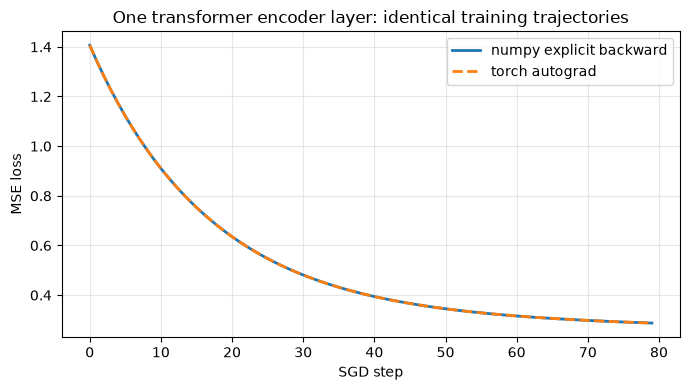

In [7]:
steps = [row[0] for row in history]
numpy_losses = [row[1] for row in history]
torch_losses = [row[2] for row in history]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(steps, numpy_losses, label="numpy explicit backward", linewidth=2)
ax.plot(steps, torch_losses, "--", label="torch autograd", linewidth=2)
ax.set_xlabel("SGD step")
ax.set_ylabel("MSE loss")
ax.set_title("One transformer encoder layer: identical training trajectories")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [8]:
initial = history[0][1]
final = history[-1][1]
print(f"loss: {initial:.6f} -> {final:.6f} ({100.0 * final / initial:.1f}% of initial)")
print(f"max |gradient diff| during training: {summary['max_grad_diff']:.2e}")
print(f"max |parameter diff| after updates:  {summary['max_parameter_diff']:.2e}")
print("state_dict keys match torch:",
      set(numpy_layer.state_dict()) == set(torch_layer.state_dict()))

torch_parameters = dict(torch_layer.named_parameters())
parameter_diff = max(
    float(np.max(np.abs(numpy_layer.params[name] - parameter.detach().numpy())))
    for name, parameter in torch_parameters.items()
)
print(f"final parameter difference:         {parameter_diff:.2e}")

loss: 1.406524 -> 0.287498 (20.4% of initial)
max |gradient diff| during training: 1.67e-16
max |parameter diff| after updates:  2.22e-16
state_dict keys match torch: True
final parameter difference:         2.22e-16
